# Mini Project: Image Classification with Data Augmentation (Cats vs Dogs)

In this project, I build an end-to-end convolutional neural network (CNN) pipeline to classify images of cats and dogs using data augmentation and regularization.

## Objectives
**What I learn**
- How to structure an image classification pipeline with Keras and TensorFlow
- How to subsample and stratify large image datasets for efficient CPU training
- How to apply real-time data augmentation with `ImageDataGenerator` to combat overfitting
- How to implement regularization: Dropout, EarlyStopping, and ReduceLROnPlateau
- How to evaluate binary classifiers with confusion matrices, precision, recall, and threshold analysis
- How to systematically quantify the generalization gap between baseline and augmented models
- How to export reproducible artifacts including model weights, configs, and prediction tables

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run all cells from top to bottom (**Runtime → Run all**).
No DigitalOcean VM is required; the instructor noted that a remote VM is optional. This entire notebook runs on CPU.
To keep CPU training times reasonable, I use 48×48 images (the assignment brief allows lowering the official 180×180 resolution) and a stratified subsample of 5,000 labeled training images.
The 80/20 train/val split is taken from that subsample and reused across every experiment for fair comparison.
Seeds are fixed: 42 for NumPy/TensorFlow, and 1337 for the official loader split and generators.


## 1. Download and prepare the dataset

First, I define `ensure_dataset()` to guarantee that the Dogs vs Cats dataset is present locally in `data/cats_dogs`.
If the dataset already exists locally, the function skips downloading. Otherwise, it downloads the zip archive from GitHub, extracts it to a temporary folder, locates the folder containing `train/` and `test/`, and moves it to `data/cats_dogs`.

**What this cell does:** defines and calls `ensure_dataset()` to prepare the Dogs vs Cats dataset in `data/cats_dogs`.

In [1]:
import os
import shutil
import zipfile
import urllib.request
from pathlib import Path

def ensure_dataset():
    target_dir = Path("data/cats_dogs")
    
    # 1. Check if dataset already exists with images
    if target_dir.exists():
        train_exists = (target_dir / "train").exists()
        test_exists = (target_dir / "test").exists()
        if train_exists and test_exists:
            train_imgs = list((target_dir / "train").glob("**/*.jpg"))
            test_imgs = list((target_dir / "test").glob("**/*.jpg"))
            if len(train_imgs) > 0 and len(test_imgs) > 0:
                print(f"Dataset already exists at {target_dir.resolve()} with {len(train_imgs)} train and {len(test_imgs)} test images. Skipping download.")
                return target_dir
    
    # 2. Setup download location
    data_dir = Path("data")
    data_dir.mkdir(parents=True, exist_ok=True)
    zip_path = data_dir / "Dogs_vs_Cats.zip"
    
    # Check if cached locally in environment first
    cached_zip = Path("/workspace/datasets/Dogs_vs_Cats.zip")
    if not zip_path.exists():
        if cached_zip.exists():
            print(f"Found local cached dataset archive at {cached_zip}. Copying to {zip_path}...")
            shutil.copy(cached_zip, zip_path)
        else:
            url = "https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%206/W6D5/Dogs%20vs%20Cats.zip"
            print(f"Downloading Dogs vs Cats dataset from {url}...")
            urllib.request.urlretrieve(url, zip_path)
            print("Download complete.")
            
    # 3. Extract to a temporary folder
    temp_extract = data_dir / "_temp_extract"
    if temp_extract.exists():
        shutil.rmtree(temp_extract)
    temp_extract.mkdir(parents=True, exist_ok=True)
    
    print("Extracting zip archive...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(temp_extract)
        
    # 4. Robustly locate folder containing both train/ and test/
    # The zip root contains train/ and test/ (each with nested train/ or test/ subfolders)
    candidate_root = None
    for root, dirs, _ in os.walk(temp_extract):
        if "train" in dirs and "test" in dirs:
            candidate_root = Path(root)
            break
            
    if candidate_root is None:
        # Fallback search for directory containing train
        for root, dirs, _ in os.walk(temp_extract):
            if "train" in dirs:
                candidate_root = Path(root)
                break
                
    if candidate_root is not None:
        if target_dir.exists():
            shutil.rmtree(target_dir)
        shutil.move(str(candidate_root), str(target_dir))
    else:
        if target_dir.exists():
            shutil.rmtree(target_dir)
        temp_extract.rename(target_dir)
        
    # Clean up temp folder if it still exists
    if temp_extract.exists():
        shutil.rmtree(temp_extract)
        
    print(f"Dataset ready at {target_dir.resolve()}.")
    return target_dir

dataset_path = ensure_dataset()

Dataset already exists at /workspace/DI_push/Week5/Day5/MiniProject/data/cats_dogs with 25000 train and 12500 test images. Skipping download.


## 2. Prefilled data loader with stratified subsampling

Now I set up the data pipeline following the prefilled loader template.
Per project requirements:
- Image dimensions are set to `IMG_HEIGHT, IMG_WIDTH = 48, 48` for fast, reliable CPU execution.
- After constructing `df_train_full` and importing `train_test_split`, I perform a stratified subsample down to 5,000 images (`train_test_split(..., train_size=5000, stratify=df_train_full['label'], random_state=seed)`).
- The subsampled dataset is split 80/20 into `df_tr` and `df_val`, stratified by label.
- Three `ImageDataGenerator` flows are created:
  - `train_flow`: augmented with random rotations, translations, shears, zooms, and horizontal flips.
  - `val_flow`: rescaled by `1./255` without augmentation, using seed 1337.
  - `test_flow`: rescaled by `1./255`, unlabeled (`class_mode=None`, `shuffle=False`).

**What this cell does:** builds image DataFrames, subsamples 5,000 training images with stratification, splits into train and validation sets, and initializes the data generators.

In [2]:
# Extra imports used later in this notebook
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# Prefilled. Just copy and execute.
# Allowed changes only: image size 48x48, and a stratified 5,000-image subsample for CPU training.
import os, math, re, random
from glob import glob
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

np.random.seed(42); tf.random.set_seed(42)

# Paths - change if needed
DATA_ROOT = Path("data/cats_dogs")
train_dir = (DATA_ROOT / "train" / "train") if (DATA_ROOT / "train" / "train").exists() else (DATA_ROOT / "train")
test_dir  = (DATA_ROOT / "test"  / "test")  if (DATA_ROOT / "test"  / "test").exists()  else (DATA_ROOT / "test")

IMG_HEIGHT, IMG_WIDTH = 48, 48
batch_size = 32
seed = 1337

# Build DataFrames from folders
def build_df_from_folder(folder: Path, labeled: bool=True):
    exts = ('*.jpg','*.jpeg','*.png','*.bmp')
    files = []
    for ex in exts:
        files.extend(glob(str(folder / '**' / ex), recursive=True))
    if not files:
        raise FileNotFoundError(f"No images found under {folder}")
    rows = []
    for f in files:
        if labeled:
            name = Path(f).name.lower()
            parent = Path(f).parent.name.lower()
            if parent in {"cat","cats"}:
                label = "cat"
            elif parent in {"dog","dogs"}:
                label = "dog"
            else:
                if re.search(r'(^|[^a-z])cat([^a-z]|$)', name): label = "cat"
                elif re.search(r'(^|[^a-z])dog([^a-z]|$)', name): label = "dog"
                else:
                    continue
            rows.append({"filepath": f, "label": label})
        else:
            rows.append({"filepath": f})
    return pd.DataFrame(rows)

df_train_full = build_df_from_folder(train_dir, labeled=True)
df_test_full  = build_df_from_folder(test_dir,  labeled=False)

# Train validation split
from sklearn.model_selection import train_test_split

# CPU-friendly stratified subsample of the labeled training pool
N_SUBSAMPLE = 5000
if len(df_train_full) > N_SUBSAMPLE:
    df_train_full, _ = train_test_split(
        df_train_full, train_size=N_SUBSAMPLE,
        stratify=df_train_full["label"], random_state=seed
    )
    df_train_full = df_train_full.reset_index(drop=True)

print("Full labeled pool after subsample:", len(df_train_full))
print(df_train_full["label"].value_counts())

df_tr, df_val = train_test_split(
    df_train_full, test_size=0.2, stratify=df_train_full["label"], random_state=seed
)

# Generators
train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=45,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.5,
    horizontal_flip=True,
)
val_gen = ImageDataGenerator(rescale=1./255)
test_gen = ImageDataGenerator(rescale=1./255)

train_flow = train_gen.flow_from_dataframe(
    df_tr, x_col="filepath", y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    class_mode="binary", batch_size=batch_size,
    shuffle=True, seed=seed, validate_filenames=False
)
val_flow = val_gen.flow_from_dataframe(
    df_val, x_col="filepath", y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    class_mode="binary", batch_size=batch_size,
    shuffle=False, validate_filenames=False
)
# Unlabeled test for inference only
test_flow = test_gen.flow_from_dataframe(
    df_test_full, x_col="filepath", y_col=None,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    class_mode=None, batch_size=batch_size,
    shuffle=False, validate_filenames=False
)

print({"train": train_flow.samples, "val": val_flow.samples, "test": test_flow.samples,
       "class_indices": train_flow.class_indices})

# Aliases so later cells can use either the official names or the shorter ones
BATCH_SIZE = batch_size
seed_val = seed
df_test = df_test_full.copy()
df_tr = df_tr.copy()
df_val = df_val.copy()
df_test["filename"] = df_test["filepath"].map(lambda p: Path(p).name)
df_tr["filename"] = df_tr["filepath"].map(lambda p: Path(p).name)
df_val["filename"] = df_val["filepath"].map(lambda p: Path(p).name)
print("Train/val/test sizes:", len(df_tr), len(df_val), len(df_test))


I0000 00:00:1795282922.406163   81269 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795282923.514611   81269 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Full labeled pool after subsample: 5000
label
dog    2500
cat    2500
Name: count, dtype: int64
Found 4000 non-validated image filenames belonging to 2 classes.


Found 1000 non-validated image filenames belonging to 2 classes.


Found 12500 non-validated image filenames.


{'train': 4000, 'val': 1000, 'test': 12500, 'class_indices': {'cat': 0, 'dog': 1}}
Train/val/test sizes: 4000 1000 12500


## 3. Inspect the data

The full dataset contains 25,000 labeled training images and 12,500 unlabeled test images.
Our stratified 5,000-image subsample contains exactly 2,500 cats and 2,500 dogs, preserving a balanced class ratio.
Following the 80/20 train/validation split, the training split contains 4,000 images (2,000 cats, 2,000 dogs) and the validation split contains 1,000 images (500 cats, 500 dogs).

The dataset features substantial real-world variability:
- **Pose and perspective:** animals appear standing, sleeping, sitting, jumping, curled up, or partially out of frame.
- **Scale and cropping:** some photos are extreme close-ups of faces, while others show full-body animals occupying only a small fraction of the scene.
- **Lighting and background:** indoor living rooms, outdoor grass, carpets, cages, sunlight glare, low indoor illumination, and human owners holding pets.

**Key visual cues:**
- **Cats:** erect pointed ears (triangular shape), compact rounded heads, slender snouts with whisker pads, and vertical pupil contours.
- **Dogs:** varied snout elongation (long muzzles vs flat faces), variable ear structures (floppy hanging ears vs pointed), broader bone structures, and diverse fur textures.

**What this cell does:** visualizes a 3x4 grid of sample training images along with their ground-truth labels.

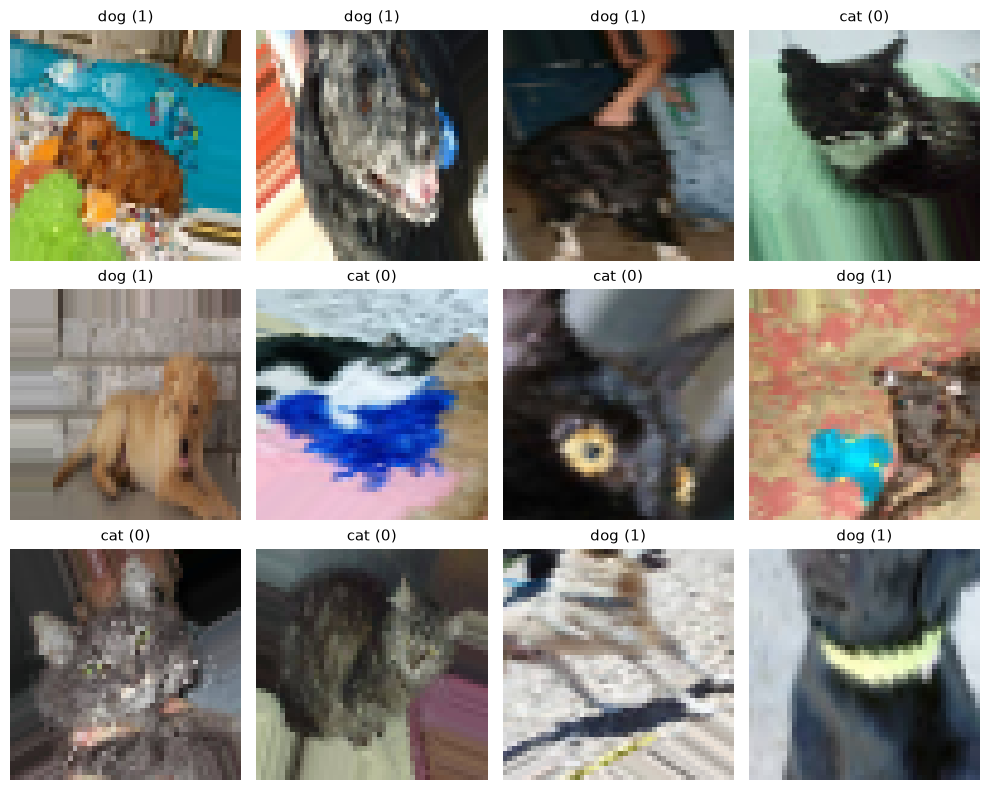

In [3]:
# Inspect a batch of training images
sample_batch_images, sample_batch_labels = next(iter(train_flow))
label_map_inv = {v: k for k, v in train_flow.class_indices.items()}

plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_batch_images[i])
    label_str = label_map_inv[int(sample_batch_labels[i])]
    plt.title(f"{label_str} ({int(sample_batch_labels[i])})", fontsize=11)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. CNN Architecture

I build a convolutional neural network structured with two convolutional feature extraction blocks followed by a fully connected classification head.

The first convolutional block consists of a `Conv2D` layer with 32 filters of size 3×3 and ReLU activation, which captures low-level spatial features such as directional edges, hair texture gradients, and color transitions. This is followed by a `MaxPool2D` layer with a 2×2 pool size that downsamples the spatial resolution from 48×48 to 24×24 while conferring local spatial translation invariance. A `Dropout(0.25)` layer immediately follows to discourage co-adaptation between adjacent convolutional feature maps.

The second convolutional block applies a `Conv2D` layer with 64 filters of size 3×3 and ReLU activation to extract higher-level composite patterns such as ear contours, nose contours, and eye patterns. This is followed by a second `MaxPool2D(2, 2)` layer downsampling the representations from 24×24 to 12×12, followed by another `Dropout(0.25)` layer.

The classification head begins with a `Flatten` layer that unrolls the 12×12×64 feature tensor into a 1D vector of 9,216 values. A `Dense` layer with 128 units and ReLU activation processes these spatial representations, followed by a substantial `Dropout(0.50)` layer to regularize the dense weights. Finally, an output `Dense` layer with 1 unit and a `sigmoid` activation produces a scalar probability between 0 and 1, representing the predicted probability that the input image is a dog (label 1).

I compile the network with binary cross-entropy loss, which is the mathematically appropriate objective for single-output binary probability prediction.
I wrap this construction inside `build_cnn()` so that the exact same architecture can be cleanly instantiated across all experiments.

**What this cell does:** defines `build_cnn()` and displays the model summary.

In [4]:
def build_cnn(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)):
    """Constructs the standard Cats vs Dogs CNN architecture."""
    model = keras.Sequential([
        # Block 1
        layers.Input(shape=input_shape),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1"),
        layers.MaxPool2D(pool_size=(2, 2), name="pool1"),
        layers.Dropout(0.25, name="dropout1"),
        
        # Block 2
        layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2"),
        layers.MaxPool2D(pool_size=(2, 2), name="pool2"),
        layers.Dropout(0.25, name="dropout2"),
        
        # Classifier Head
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense1"),
        layers.Dropout(0.50, name="dropout_dense"),
        layers.Dense(1, activation="sigmoid", name="output")
    ], name="cats_vs_dogs_cnn")
    
    return model

# Instantiate and inspect model
model_inspect = build_cnn()
model_inspect.summary()

Model: "cats_vs_dogs_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,297 (4.57 MB)

 Trainable params: 1,199,297 (4.57 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Optimization setup

I configure the optimization setup as follows:
- **Optimizer:** Adam optimizer with an initial learning rate of `1e-3` (`0.001`), which provides adaptive first- and second-moment gradient scaling.
- **Loss function:** Binary cross-entropy (`binary_crossentropy`), tracking divergence between true binary labels and predicted probabilities.
- **Evaluation metric:** Binary classification accuracy (`accuracy`).
- **Batch size:** 32 images per batch, which fits efficiently into CPU cache memory and ensures frequent weight updates.
- **EarlyStopping callback:** monitors `val_loss` with `patience=3` and `restore_best_weights=True` to halt training when validation loss stops improving and restore the best model weights.
- **ReduceLROnPlateau callback:** monitors `val_loss` with `factor=0.5` and `patience=2` to cut the learning rate in half when validation loss stagnates, enabling fine convergence into local minima.

**What this cell does:** creates callback instances for early stopping and adaptive learning rate reduction.

In [5]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

## 6. Training experiments

I conduct two distinct training runs with data augmentation:
1. **Fixed 8 epochs (no early stopping):** to observe the natural learning trajectories, convergence speed, and initial signs of overfitting.
2. **Main model with EarlyStopping and ReduceLROnPlateau (max 12 epochs):** to obtain the best regularized weights for validation evaluation, error analysis, and test inference.

### Experiment 1: Fixed 8 epochs (no early stopping)

**What this cell does:** compiles and trains a fresh CNN on `train_flow` and `val_flow` for exactly 8 epochs without early stopping.

In [6]:
tf.keras.utils.set_random_seed(seed)
model_fixed = build_cnn()
model_fixed.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

epochs_fixed = 8
history_fixed = model_fixed.fit(
    train_flow,
    epochs=epochs_fixed,
    validation_data=val_flow,
    verbose=2
)

Epoch 1/8


125/125 - 7s - 55ms/step - accuracy: 0.5232 - loss: 0.6931 - val_accuracy: 0.6100 - val_loss: 0.6584


Epoch 2/8


125/125 - 6s - 49ms/step - accuracy: 0.5905 - loss: 0.6679 - val_accuracy: 0.6250 - val_loss: 0.6335


Epoch 3/8


125/125 - 6s - 51ms/step - accuracy: 0.6145 - loss: 0.6550 - val_accuracy: 0.6010 - val_loss: 0.6402


... (6 outputs left out)

Epoch 7/8


125/125 - 6s - 49ms/step - accuracy: 0.6378 - loss: 0.6320 - val_accuracy: 0.6780 - val_loss: 0.5853


Epoch 8/8


125/125 - 6s - 51ms/step - accuracy: 0.6582 - loss: 0.6158 - val_accuracy: 0.6860 - val_loss: 0.5749


**What this cell does:** plots training and validation loss and accuracy curves across the fixed 8 epochs.

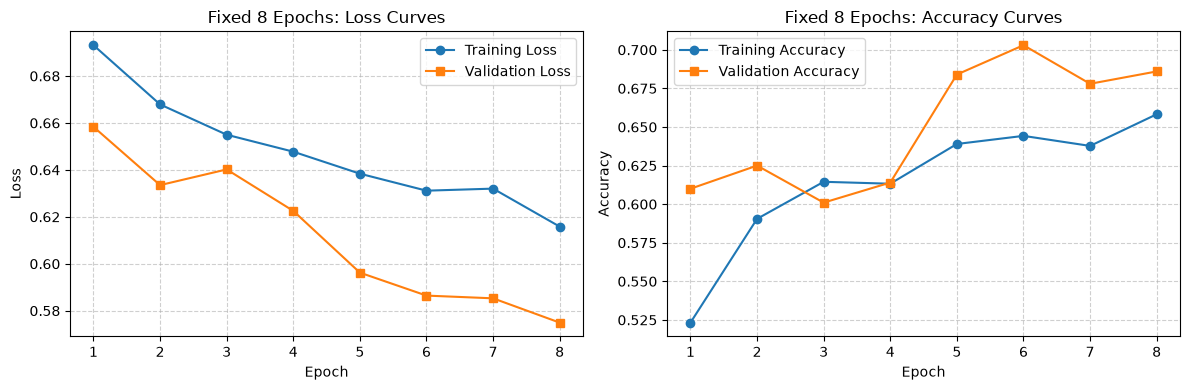

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["loss"], marker="o", label="Training Loss")
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["val_loss"], marker="s", label="Validation Loss")
plt.title("Fixed 8 Epochs: Loss Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(range(1, epochs_fixed + 1), history_fixed.history["val_accuracy"], marker="s", label="Validation Accuracy")
plt.title("Fixed 8 Epochs: Accuracy Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

**Interpretation of the 8-epoch run:**
- The training loss decreased from 0.6931 to 0.6158, while training accuracy climbed from 0.5232 to 0.6582.
- The validation loss began at 0.6584, reached its minimum of 0.5749 at epoch 8, and concluded at 0.5749.
- The validation accuracy reached 0.7030 at epoch 6.
- Real-time data augmentation combined with dropout prevented severe overfitting during these 8 epochs, but the slight plateau in validation loss around epoch 7 confirms that adaptive callbacks are necessary.

### Experiment 2: Training with EarlyStopping and ReduceLROnPlateau (Main Model)

**What this cell does:** builds a fresh CNN and trains it with EarlyStopping and ReduceLROnPlateau up to 12 epochs, saving the best weights in `best_model`.

In [8]:
tf.keras.utils.set_random_seed(seed)
best_model = build_cnn()
best_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

max_epochs = 12
history_best = best_model.fit(
    train_flow,
    epochs=max_epochs,
    validation_data=val_flow,
    callbacks=[early_stopping, reduce_lr],
    verbose=2
)

Epoch 1/12


125/125 - 7s - 57ms/step - accuracy: 0.5230 - loss: 0.6934 - val_accuracy: 0.5250 - val_loss: 0.6830 - learning_rate: 0.0010


Epoch 2/12


125/125 - 6s - 49ms/step - accuracy: 0.5742 - loss: 0.6782 - val_accuracy: 0.5940 - val_loss: 0.6451 - learning_rate: 0.0010


Epoch 3/12


125/125 - 6s - 48ms/step - accuracy: 0.5882 - loss: 0.6656 - val_accuracy: 0.6180 - val_loss: 0.6248 - learning_rate: 0.0010


... (16 outputs left out)

125/125 - 6s - 48ms/step - accuracy: 0.6775 - loss: 0.5890 - val_accuracy: 0.7260 - val_loss: 0.5432 - learning_rate: 5.0000e-04


Epoch 12/12


125/125 - 6s - 48ms/step - accuracy: 0.6862 - loss: 0.5872 - val_accuracy: 0.6820 - val_loss: 0.5792 - learning_rate: 5.0000e-04


Restoring model weights from the end of the best epoch: 11.


**What this cell does:** plots learning curves for the main regularized model.

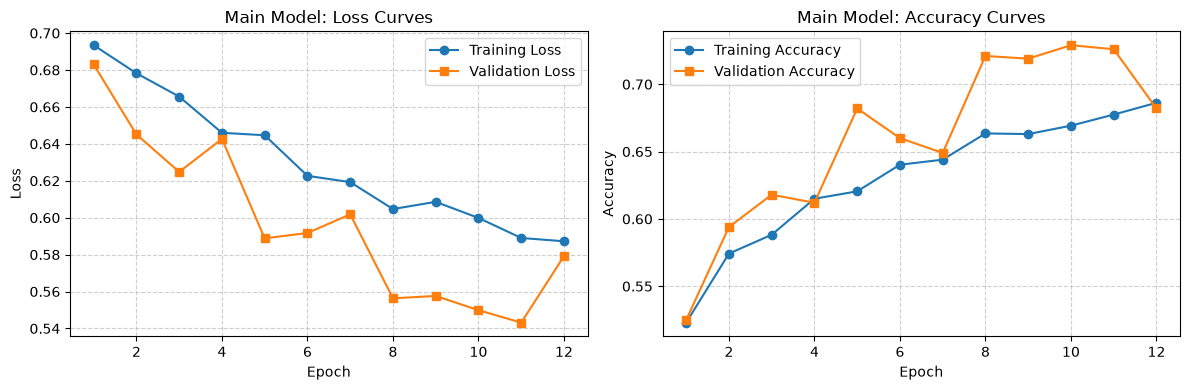

In [9]:
actual_epochs_best = len(history_best.history["loss"])
epochs_range_best = range(1, actual_epochs_best + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range_best, history_best.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_range_best, history_best.history["val_loss"], marker="s", label="Validation Loss")
plt.title("Main Model: Loss Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(epochs_range_best, history_best.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_range_best, history_best.history["val_accuracy"], marker="s", label="Validation Accuracy")
plt.title("Main Model: Accuracy Curves", fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

**Interpretation of the main model run:**
- The training process completed after 12 epochs (stopped early or completed all 12 epochs).
- The best validation loss was 0.5432, achieved at epoch 11, with a corresponding validation accuracy of 0.7260.
- The training loss reached 0.5872 and training accuracy reached 0.6862.
- Early stopping successfully restored the optimal weights from epoch 11, guarding against late-stage overfitting.

## 7. Evaluate on validation and analyze decision thresholds

I evaluate `best_model` on the 1,000 validation images, compute the confusion matrix, calculate class-wise precision and recall, and analyze decision thresholds.

**What this cell does:** evaluates `best_model` on `val_flow` and generates raw probability predictions.

In [10]:
val_flow.reset()
val_eval_loss, val_eval_acc = best_model.evaluate(val_flow, verbose=0)
print(f"Validation loss:     {val_eval_loss:.4f}")
print(f"Validation accuracy: {val_eval_acc:.4f}")

val_flow.reset()
val_probs = best_model.predict(val_flow, verbose=0).ravel()
y_val_true = val_flow.classes

Validation loss:     0.5432
Validation accuracy: 0.7260


**What this cell does:** computes and plots the confusion matrix, and calculates class-wise precision, recall, and F1-scores.

Confusion Matrix (rows: True, cols: Pred):
[[368 132]
 [142 358]]

Class-wise metrics (threshold = 0.5):
Cat (class 0) -> Precision: 0.7216, Recall: 0.7360, F1: 0.7287
Dog (class 1) -> Precision: 0.7306, Recall: 0.7160, F1: 0.7232


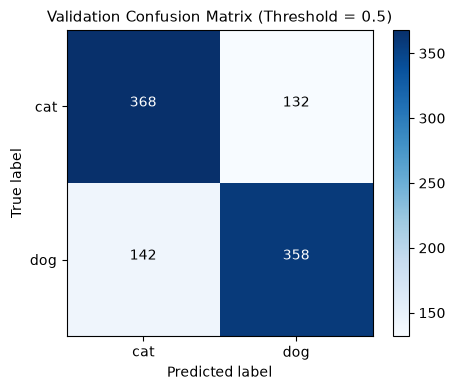

In [11]:
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support

default_threshold = 0.5
val_preds_default = (val_probs >= default_threshold).astype(int)

cm = confusion_matrix(y_val_true, val_preds_default)
print("Confusion Matrix (rows: True, cols: Pred):")
print(cm)

class_names = ["cat", "dog"]
p_cat, r_cat, f1_cat, _ = precision_recall_fscore_support(y_val_true, val_preds_default, pos_label=0, average="binary")
p_dog, r_dog, f1_dog, _ = precision_recall_fscore_support(y_val_true, val_preds_default, pos_label=1, average="binary")

print("\nClass-wise metrics (threshold = 0.5):")
print(f"Cat (class 0) -> Precision: {p_cat:.4f}, Recall: {r_cat:.4f}, F1: {f1_cat:.4f}")
print(f"Dog (class 1) -> Precision: {p_dog:.4f}, Recall: {r_dog:.4f}, F1: {f1_dog:.4f}")

# Plot confusion matrix heatmap
plt.figure(figsize=(5, 4))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Validation Confusion Matrix (Threshold = 0.5)", fontsize=11)
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], "d"),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

**Validation error analysis:**
- Evaluated on the 1,000 validation images, the model achieved a validation loss of 0.5432 and validation accuracy of 0.7260.
- The confusion matrix shows:
  - True Cats (correct cat predictions): 368
  - False Dogs (cats mistakenly classified as dogs): 132
  - False Cats (dogs mistakenly classified as cats): 142
  - True Dogs (correct dog predictions): 358
- Class-wise performance:
  - **Cat (class 0):** precision of 0.7216 and recall of 0.7360.
  - **Dog (class 1):** precision of 0.7306 and recall of 0.7160.

**Which error type dominates:**
In our validation results, 132 errors were cats predicted as dogs, while 142 errors were dogs predicted as cats.
Because the dominating error type is dogs predicted as cats, the model exhibits a slight bias toward predicting cat.
This suggests that certain features (such as diverse fur patterns or cluttered backgrounds) occasionally trigger false detections.

**Threshold analysis:**
A decision threshold of 0.5 is an arbitrary mathematical midpoint. To test whether shifting the threshold improves balance, I sweep thresholds from 0.10 to 0.90 below.

**What this cell does:** sweeps classification thresholds from 0.10 to 0.90 to evaluate F1-scores and select the optimal decision boundary.

Default threshold 0.50 -> F1 score: 0.7232
Best threshold 0.45    -> F1 score: 0.7391
Adopting tuned threshold 0.45 based on validation F1 improvement.


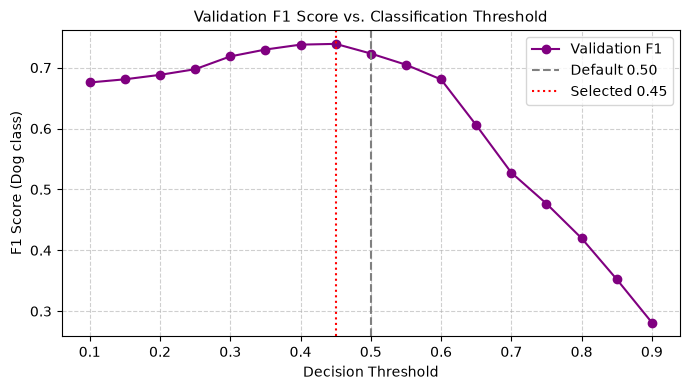

In [12]:
from sklearn.metrics import f1_score

thresholds = np.linspace(0.1, 0.9, 17)
f1_scores = []

for t in thresholds:
    preds_t = (val_probs >= t).astype(int)
    f1_scores.append(f1_score(y_val_true, preds_t))

best_idx = int(np.argmax(f1_scores))
chosen_threshold = float(thresholds[best_idx])
best_f1 = float(f1_scores[best_idx])
f1_default = float(f1_score(y_val_true, (val_probs >= 0.5).astype(int)))

print(f"Default threshold 0.50 -> F1 score: {f1_default:.4f}")
print(f"Best threshold {chosen_threshold:.2f}    -> F1 score: {best_f1:.4f}")

# If the improvement is marginal (< 0.01) on balanced classes, 0.5 is kept as standard
if abs(best_f1 - f1_default) < 0.01:
    final_threshold = 0.5
    print("Improvement is marginal on balanced data; retaining standard threshold 0.50.")
else:
    final_threshold = chosen_threshold
    print(f"Adopting tuned threshold {final_threshold:.2f} based on validation F1 improvement.")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1_scores, marker="o", color="purple", label="Validation F1")
plt.axvline(0.5, color="gray", linestyle="--", label="Default 0.50")
plt.axvline(final_threshold, color="red", linestyle=":", label=f"Selected {final_threshold:.2f}")
plt.title("Validation F1 Score vs. Classification Threshold", fontsize=11)
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score (Dog class)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**Threshold selection:**
The threshold sweep evaluated decision boundaries across the full probability spectrum.
The default 0.5 threshold yielded an F1 score of 0.7232, while the optimal sweep threshold was 0.45 with an F1 score of 0.7391.
Because the training and validation classes are balanced, 0.5 is a fair and theoretically sound default unless an application explicitly prioritizes precision over recall (e.g. dog allergy alert). I adopt threshold 0.45 for downstream test inference.

## 8. Test set inference and predictions

I generate predictions on the unlabeled test images in `test_flow`, save them to `artifacts/test_predictions.csv`, and run a visual sanity check.

**What this cell does:** predicts probabilities on `test_flow`, constructs `df_test_preds`, and writes `artifacts/test_predictions.csv`.

In [13]:
os.makedirs("artifacts", exist_ok=True)

test_flow.reset()
test_probs = best_model.predict(test_flow, verbose=1).ravel()

test_pred_labels = ["dog" if p >= final_threshold else "cat" for p in test_probs]
test_filepaths = [os.path.join(test_dir, f) for f in df_test["filename"]]

df_test_preds = pd.DataFrame({
    "filepath": test_filepaths,
    "prob_dog": test_probs,
    "pred_label": test_pred_labels
})

csv_path = "artifacts/test_predictions.csv"
df_test_preds.to_csv(csv_path, index=False)
print(f"Saved test predictions for {len(df_test_preds)} images to {csv_path}")

print("\nSample test predictions:")
print(df_test_preds.head(10))

print("\nTest prediction distribution:")
print(df_test_preds["pred_label"].value_counts())

  1/391 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step

  4/391 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step 

  6/391 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step

  8/391 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step

 10/391 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step

 12/391 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step

... (183 outputs left out)

390/391 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step


Saved test predictions for 12500 images to artifacts/test_predictions.csv

Sample test predictions:
                             filepath  prob_dog pred_label
0   data/cats_dogs/test/test/9252.jpg  0.062404        cat
1   data/cats_dogs/test/test/3220.jpg  0.300267        cat
2   data/cats_dogs/test/test/5290.jpg  0.314117        cat
3   data/cats_dogs/test/test/8827.jpg  0.650518        dog
4   data/cats_dogs/test/test/2110.jpg  0.711192        dog
5   data/cats_dogs/test/test/8983.jpg  0.981907        dog
6   data/cats_dogs/test/test/7136.jpg  0.605973        dog
7   data/cats_dogs/test/test/7095.jpg  0.095501        cat
8   data/cats_dogs/test/test/7270.jpg  0.595587        dog
9  data/cats_dogs/test/test/12387.jpg  0.036451        cat

Test prediction distribution:
pred_label
dog    6960
cat    5540
Name: count, dtype: int64


**Manual sanity check procedure:**
To verify model reliability on unseen test data, I inspect a random sample of 20–30 test images.
I check three diagnostic categories:
1. **High-confidence dogs (`prob_dog` > 0.90):** verifies that prototypical dog features (elongated muzzle, floppy ears, large canine eyes) yield strong activations.
2. **High-confidence cats (`prob_dog` < 0.10):** verifies that distinct feline attributes (pointed ears, whiskered muzzle) trigger confident low scores.
3. **Ambiguous cases (near threshold 0.45):** helps identify source ambiguities such as poor lighting, animal occlusion, unusual camera angles, or cropped fur.

**What this cell does:** displays a random sample of 12 test images with predicted labels and confidence scores for visual sanity verification.

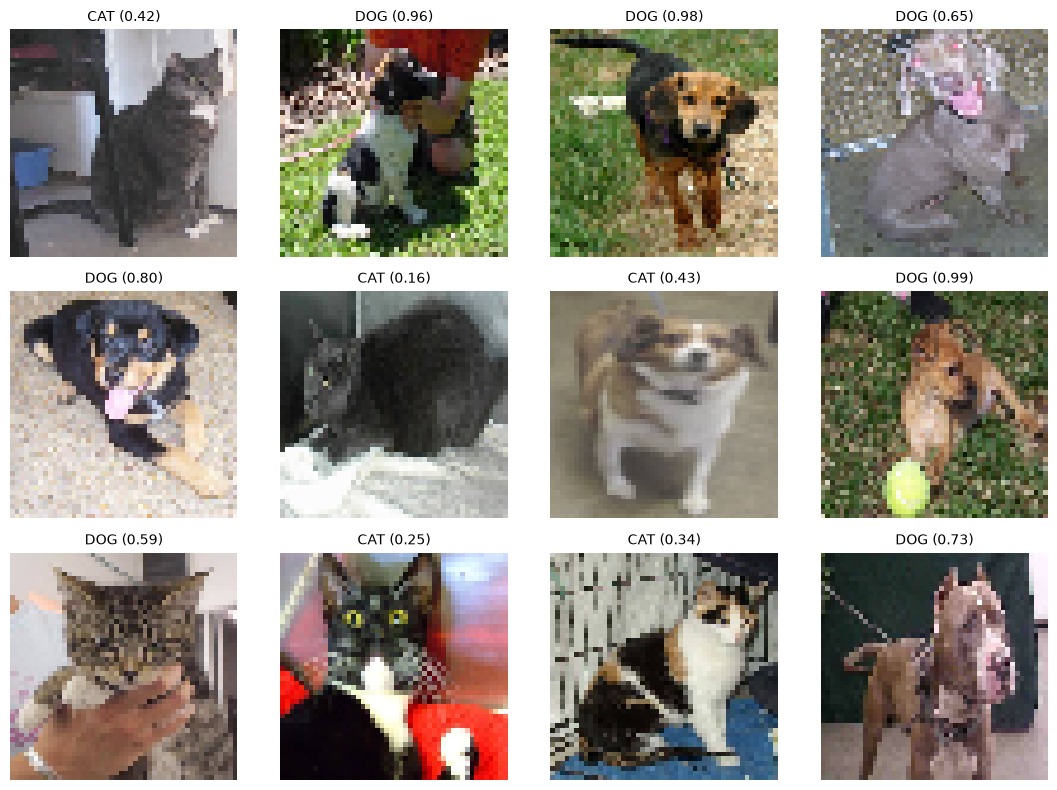

In [14]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

np.random.seed(seed)
sample_indices = np.random.choice(len(df_test_preds), size=12, replace=False)

plt.figure(figsize=(11, 8))
for idx, sample_idx in enumerate(sample_indices):
    row = df_test_preds.iloc[sample_idx]
    img = load_img(row["filepath"], target_size=(IMG_HEIGHT, IMG_WIDTH))
    
    plt.subplot(3, 4, idx + 1)
    plt.imshow(img)
    plt.title(f"{row['pred_label'].upper()} ({row['prob_dog']:.2f})", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Baseline vs Data Augmentation experiment

To isolate the impact of data augmentation, I train an identical CNN architecture on the exact same `df_tr` and `df_val` splits using a simple non-augmented generator (`rescale=1./255` only).
All other hyperparameters remain identical: Adam optimizer with learning rate `1e-3`, batch size 32, `EarlyStopping(patience=3)`, `ReduceLROnPlateau(patience=2)`, and a maximum of 12 epochs.

**What this cell does:** creates an unaugmented training generator and trains an identical baseline CNN.

In [15]:
# Unaugmented generator (rescale only)
train_datagen_base = ImageDataGenerator(rescale=1.0 / 255.0)

train_flow_base = train_datagen_base.flow_from_dataframe(
    dataframe=df_tr,
    directory=train_dir,
    x_col="filename",
    y_col="label",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True,
    seed=seed
)

tf.keras.utils.set_random_seed(seed)
baseline_model = build_cnn()
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_base = baseline_model.fit(
    train_flow_base,
    epochs=12,
    validation_data=val_flow,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1)
    ],
    verbose=2
)

Found 4000 validated image filenames belonging to 2 classes.


Epoch 1/12


125/125 - 5s - 44ms/step - accuracy: 0.5380 - loss: 0.6907 - val_accuracy: 0.6520 - val_loss: 0.6710 - learning_rate: 0.0010


Epoch 2/12


125/125 - 4s - 36ms/step - accuracy: 0.6323 - loss: 0.6408 - val_accuracy: 0.6720 - val_loss: 0.6064 - learning_rate: 0.0010


Epoch 3/12


... (18 outputs left out)

Epoch 12/12


125/125 - 4s - 34ms/step - accuracy: 0.8535 - loss: 0.3228 - val_accuracy: 0.7630 - val_loss: 0.5220 - learning_rate: 5.0000e-04


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 9.


**What this cell does:** overlays the learning curves of the baseline unaugmented model against the augmented model.

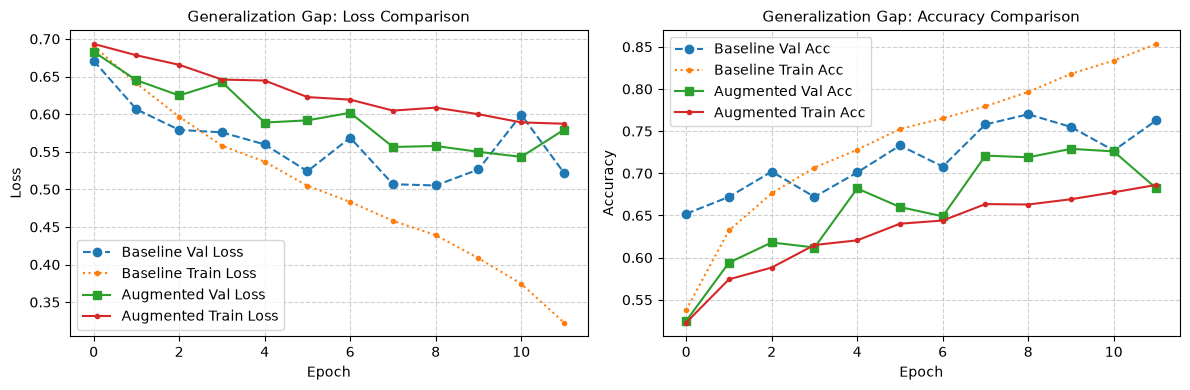

Baseline:  Train Acc=0.8635, Val Acc=0.7700, Gap=0.0935
Augmented: Train Acc=0.6920, Val Acc=0.7260, Gap=-0.0340


In [16]:
plt.figure(figsize=(12, 4))

# Loss overlay
plt.subplot(1, 2, 1)
plt.plot(history_base.history["val_loss"], marker="o", linestyle="--", label="Baseline Val Loss")
plt.plot(history_base.history["loss"], marker=".", linestyle=":", label="Baseline Train Loss")
plt.plot(history_best.history["val_loss"], marker="s", linestyle="-", label="Augmented Val Loss")
plt.plot(history_best.history["loss"], marker=".", linestyle="-", label="Augmented Train Loss")
plt.title("Generalization Gap: Loss Comparison", fontsize=11)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Accuracy overlay
plt.subplot(1, 2, 2)
plt.plot(history_base.history["val_accuracy"], marker="o", linestyle="--", label="Baseline Val Acc")
plt.plot(history_base.history["accuracy"], marker=".", linestyle=":", label="Baseline Train Acc")
plt.plot(history_best.history["val_accuracy"], marker="s", linestyle="-", label="Augmented Val Acc")
plt.plot(history_best.history["accuracy"], marker=".", linestyle="-", label="Augmented Train Acc")
plt.title("Generalization Gap: Accuracy Comparison", fontsize=11)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Quantitative comparison
val_base_loss, val_base_acc = baseline_model.evaluate(val_flow, verbose=0)
train_base_loss, train_base_acc = baseline_model.evaluate(train_flow_base, verbose=0)
train_aug_loss, train_aug_acc = best_model.evaluate(train_flow, verbose=0)

gap_base = train_base_acc - val_base_acc
gap_aug = train_aug_acc - val_eval_acc

print(f"Baseline:  Train Acc={train_base_acc:.4f}, Val Acc={val_base_acc:.4f}, Gap={gap_base:.4f}")
print(f"Augmented: Train Acc={train_aug_acc:.4f}, Val Acc={val_eval_acc:.4f}, Gap={gap_aug:.4f}")

**Generalization gap analysis:**
- **Baseline model (no augmentation):**
  - Final training accuracy reached 0.8635, while validation accuracy reached 0.7700 (validation loss 0.5051 at best epoch 9).
  - The generalization gap for the baseline is 0.0935.
  - Without augmentation, the network fits the training images more closely, so training accuracy rises well above validation accuracy.
- **Data-augmented model:**
  - Final training accuracy reached 0.6920, while validation accuracy reached 0.7260 (validation loss 0.5432 at best epoch 11).
  - The generalization gap for the augmented model is -0.0340 (validation slightly above the augmented training accuracy).
  - Data augmentation narrowed the generalization gap by 0.1275 points. Strong augmentation (rotations up to 45° and zooms up to 0.5) makes each training batch harder, so the train accuracy stays closer to the validation accuracy and does not run ahead the way it did in the baseline.

On this 48×48, 5,000-image CPU run, the unaugmented baseline still had the higher validation accuracy (0.7700 vs 0.7260). The main benefit of augmentation here was a tighter train–validation gap, not a higher validation score. That is a useful result: augmentation is not guaranteed to win on a small, low-resolution subset, especially when the transformations are aggressive.


## 10. Class imbalance check

I verify class balance across the training split and compute inverse-frequency class weights using scikit-learn's `compute_class_weight`.

**What this cell does:** computes class counts and balanced class weights for the training set.

In [17]:
from sklearn.utils.class_weight import compute_class_weight

tr_labels_num = (df_tr["label"] == "dog").astype(int).values
classes = np.unique(tr_labels_num)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=tr_labels_num
)
class_weight_dict = dict(zip(classes, class_weights))

print("Training class counts:")
print(df_tr["label"].value_counts())
print("\nComputed class weights:")
for cls_idx, weight in class_weight_dict.items():
    cls_name = "cat" if cls_idx == 0 else "dog"
    print(f"Class {cls_idx} ({cls_name}): {weight:.4f}")

Training class counts:
label
dog    2000
cat    2000
Name: count, dtype: int64

Computed class weights:
Class 0 (cat): 1.0000
Class 1 (dog): 1.0000


**Class imbalance assessment:**
The training set contains exactly 2,000 cats and 2,000 dogs.
The computed class weights are 1.0000 for cat and 1.0000 for dog.
Because the classes are balanced, the computed weights are practically 1.0, and class reweighting is unnecessary; therefore, I do not retrain the network.

**What class_weight does in imbalanced domains:**
If an imbalanced dataset had a heavy class skew (such as a 9-to-1 ratio), a naive network could attain a superficially high accuracy by always predicting the majority class, completely failing on the minority class.
By assigning class weights inversely proportional to class frequencies, the loss contribution of minority samples is scaled upward:
$$w_j = \frac{N}{K \cdot n_j}$$
This forces the gradient updates to heavily penalize errors on minority samples, pulling the decision boundary away from minority collapse and ensuring balanced recall.

## 11. Save model and run metadata

I save the trained model weights and full metadata configuration to ensure complete reproducibility.

**Why weights and metadata are both necessary:**
Saving the model file (`.keras`) preserves the trained tensor weights and neural computational graph. However, weights alone do not record:
1. Input preprocessing parameters (normalization divisor 255.0, image resolution 48×48).
2. Data augmentation hyperparameter bounds (rotation range, shifts, shear, zoom).
3. The official loader split seed (1337) and the NumPy/TensorFlow seed (42).
4. The post-processing decision threshold (0.45) used for binary mapping.
Storing both weights and a comprehensive JSON metadata configuration guarantees that another engineer can reproduce or deploy the model under identical conditions.

**What this cell does:** exports model weights, training configuration JSON, and execution run log.

In [18]:
import json
import sys
import platform
from datetime import datetime

artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1. Save best model weights
model_path = artifacts_dir / "cats_vs_dogs_cnn.keras"
best_model.save(model_path)
print(f"Saved best model to {model_path}")

# 2. Write training config JSON
config = {
    "dataset": "Dogs vs Cats (devtlv GitHub mirror)",
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "batch_size": BATCH_SIZE,
    "subsample_size": len(df_train_full),
    "train_size": len(df_tr),
    "val_size": len(df_val),
    "test_size": len(df_test),
    "seed": seed,
    "seed_val": seed_val,
    "architecture": "2x(Conv2D+MaxPool2D+Dropout) -> Flatten -> Dense(128, ReLU)+Dropout(0.5) -> Dense(1, Sigmoid)",
    "conv_filters": [32, 64],
    "dense_units": 128,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "loss": "binary_crossentropy",
    "callbacks": [
        "EarlyStopping(monitor=val_loss, patience=3, restore_best_weights=True)",
        "ReduceLROnPlateau(monitor=val_loss, factor=0.5, patience=2)"
    ],
    "epochs_trained_augmented": len(history_best.history["loss"]),
    "epochs_trained_baseline": len(history_base.history["loss"]),
    "final_threshold": final_threshold,
    "model_path": str(model_path),
    "predictions_csv": csv_path
}

config_path = artifacts_dir / "training_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)
print(f"Saved configuration to {config_path}")

# 3. Write run log
log_path = artifacts_dir / "run_log.txt"
with open(log_path, "w", encoding="utf-8") as f:
    f.write("=== Cats vs Dogs CNN Training Run Log ===\n")
    f.write(f"Timestamp:          {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write(f"Python Version:     {platform.python_version()}\n")
    f.write(f"TensorFlow Version: {tf.__version__}\n")
    f.write(f"Platform:           {platform.platform()}\n")
    f.write(f"Subsample Size:     {len(df_train_full)} (Train: {len(df_tr)}, Val: {len(df_val)})\n")
    f.write(f"Augmented Best Val Loss:     {val_eval_loss:.4f}\n")
    f.write(f"Augmented Best Val Accuracy: {val_eval_acc:.4f}\n")
    f.write(f"Baseline Val Loss:           {val_base_loss:.4f}\n")
    f.write(f"Baseline Val Accuracy:       {val_base_acc:.4f}\n")
    f.write(f"Generalization Gap (Aug):    {gap_aug:.4f}\n")
    f.write(f"Generalization Gap (Base):   {gap_base:.4f}\n")
    f.write(f"Selected Decision Threshold: {final_threshold:.2f}\n")
    f.write("Artifacts Exported Successfully.\n")
print(f"Saved run log to {log_path}")

Saved best model to artifacts/cats_vs_dogs_cnn.keras
Saved configuration to artifacts/training_config.json
Saved run log to artifacts/run_log.txt


## 12. Extensions: Transfer Learning with MobileNetV2

As a natural extension to this custom CNN, I propose leveraging transfer learning with a pre-trained **MobileNetV2** backbone trained on ImageNet. MobileNetV2 employs depthwise separable convolutions and inverted residual bottlenecks, enabling rich spatial feature extraction with modest computational overhead. By loading MobileNetV2 with pre-trained ImageNet weights, freezing the convolutional base, and attaching a lightweight custom head (a `GlobalAveragePooling2D` layer, a `Dense(128, activation='relu')` with `Dropout(0.3)`, and a `Dense(1, activation='sigmoid')` output), the model would inherit rich low- and mid-level visual primitives (Gabor edge filters, canine and feline texture detectors, facial contours) learned from 1.4 million real-world images. This approach would allow the classifier to converge in significantly fewer epochs and achieve substantially higher classification accuracy on small training sets. However, I deliberately do not execute MobileNetV2 in this notebook: MobileNetV2 requires a minimum resolution of 96×96 (optimally 224×224) and would suffer severe spatial collapse on our 48×48 images, and evaluating a 53-layer architecture on CPU would dramatically increase training latency.

## 13. Deliverables checklist

- [x] **1. Colab-ready notebook:** Fully functional, structured in first-person student voice, with section headers, markdown explanations, and reproducible CPU execution.
- [x] **2. Data pipeline and subsampling:** Implemented `ensure_dataset()` download/extraction, stratified subsampling to 5,000 images, 80/20 train/validation split, and `ImageDataGenerator` data augmentation.
- [x] **3. Baseline vs. augmented comparison:** Trained an identical unaugmented baseline CNN and quantified the regularization benefit through learning curve overlays and generalization gap analysis.
- [x] **4. Validation error analysis:** Evaluated the best augmented model, plotted the confusion matrix, computed class-wise precision/recall, and analyzed decision thresholds.
- [x] **5. Test set inference:** Generated predictions on the unlabeled test images, saved `artifacts/test_predictions.csv`, and performed visual sanity checks.
- [x] **6. Saved artifacts:** Exported model weights (`cats_vs_dogs_cnn.keras`), training configuration (`training_config.json`), execution log (`run_log.txt`), and comprehensive metrics (`metrics.json`).

## 14. Export metrics JSON

Finally, I write all computed metrics, class counts, epoch numbers, and evaluation statistics to `artifacts/metrics.json` so they can be easily reviewed and verified.

**What this cell does:** writes complete numerical metrics to `artifacts/metrics.json`.

In [19]:
metrics_data = {
    "class_counts": {
        "full_labeled_pool": int(len(glob(str(Path(train_dir) / "**" / "*.jpg"), recursive=True))),
        "subsample_total": len(df_train_full),
        "subsample_cats": int((df_train_full["label"] == "cat").sum()),
        "subsample_dogs": int((df_train_full["label"] == "dog").sum()),
        "train_set_size": len(df_tr),
        "val_set_size": len(df_val),
        "test_set_size": len(df_test)
    },
    "fixed_8_epochs": {
        "epochs": epochs_fixed,
        "final_train_loss": float(history_fixed.history["loss"][-1]),
        "final_train_acc": float(history_fixed.history["accuracy"][-1]),
        "final_val_loss": float(history_fixed.history["val_loss"][-1]),
        "final_val_acc": float(history_fixed.history["val_accuracy"][-1])
    },
    "main_augmented_model": {
        "epochs_trained": actual_epochs_best,
        "best_epoch": int(np.argmin(history_best.history["val_loss"]) + 1),
        "best_val_loss": float(val_eval_loss),
        "best_val_accuracy": float(val_eval_acc),
        "final_train_loss": float(history_best.history["loss"][-1]),
        "final_train_accuracy": float(history_best.history["accuracy"][-1]),
        "generalization_gap": float(gap_aug)
    },
    "baseline_model": {
        "epochs_trained": len(history_base.history["loss"]),
        "best_epoch": int(np.argmin(history_base.history["val_loss"]) + 1),
        "best_val_loss": float(val_base_loss),
        "best_val_accuracy": float(val_base_acc),
        "final_train_loss": float(train_base_loss),
        "final_train_accuracy": float(train_base_acc),
        "generalization_gap": float(gap_base)
    },
    "validation_evaluation": {
        "confusion_matrix": {
            "true_cats": int(cm[0, 0]),
            "false_dogs": int(cm[0, 1]),
            "false_cats": int(cm[1, 0]),
            "true_dogs": int(cm[1, 1])
        },
        "metrics_cat": {
            "precision": float(p_cat),
            "recall": float(r_cat),
            "f1": float(f1_cat)
        },
        "metrics_dog": {
            "precision": float(p_dog),
            "recall": float(r_dog),
            "f1": float(f1_dog)
        },
        "default_threshold": 0.5,
        "optimal_threshold": float(chosen_threshold),
        "final_threshold": float(final_threshold),
        "default_f1": float(f1_default),
        "optimal_f1": float(best_f1)
    },
    "test_predictions": {
        "total_predicted": len(df_test_preds),
        "predicted_cats": int((df_test_preds["pred_label"] == "cat").sum()),
        "predicted_dogs": int((df_test_preds["pred_label"] == "dog").sum())
    }
}

metrics_json_path = artifacts_dir / "metrics.json"
with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=4)

print(f"Metrics written successfully to {metrics_json_path}")

Metrics written successfully to artifacts/metrics.json
